In [1]:
import pandas as pd
import numpy as np

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.base import BaseEstimator, TransformerMixin
from scipy.cluster.hierarchy import dendrogram, linkage

In [3]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import silhouette_score


In [4]:
df = pd.read_excel("../data/clustering/Online Retail.xlsx")

In [5]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


In [7]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [8]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [9]:
def data_report():
    print("NA :")
    print(df.isna().sum())
    print("dupe: ")
    print(df.duplicated().sum())

In [10]:
data_report()

NA :
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64
dupe: 
5268


In [11]:
df.drop_duplicates(inplace=True)

In [12]:
df.Country.unique()

<StringArray>
[      'United Kingdom',               'France',            'Australia',
          'Netherlands',              'Germany',               'Norway',
                 'EIRE',          'Switzerland',                'Spain',
               'Poland',             'Portugal',                'Italy',
              'Belgium',            'Lithuania',                'Japan',
              'Iceland',      'Channel Islands',              'Denmark',
               'Cyprus',               'Sweden',              'Austria',
               'Israel',              'Finland',              'Bahrain',
               'Greece',            'Hong Kong',            'Singapore',
              'Lebanon', 'United Arab Emirates',         'Saudi Arabia',
       'Czech Republic',               'Canada',          'Unspecified',
               'Brazil',                  'USA',   'European Community',
                'Malta',                  'RSA']
Length: 38, dtype: str

In [13]:
df = df.dropna(subset=['CustomerID'])

In [14]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [15]:
df = df[~df['InvoiceNo'].astype(str).str.startswith('C')]

removing all cancelled orderes

In [16]:
df.info()

<class 'pandas.DataFrame'>
Index: 392732 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    392732 non-null  object        
 1   StockCode    392732 non-null  object        
 2   Description  392732 non-null  object        
 3   Quantity     392732 non-null  int64         
 4   InvoiceDate  392732 non-null  datetime64[us]
 5   UnitPrice    392732 non-null  float64       
 6   CustomerID   392732 non-null  float64       
 7   Country      392732 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 27.0+ MB


In [17]:
df = df.drop(labels=['StockCode','Description'],axis=1)

In [18]:
X_train = df

In [19]:
X_train.head()

,InvoiceNo,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


<Axes: xlabel='Country', ylabel='Count'>

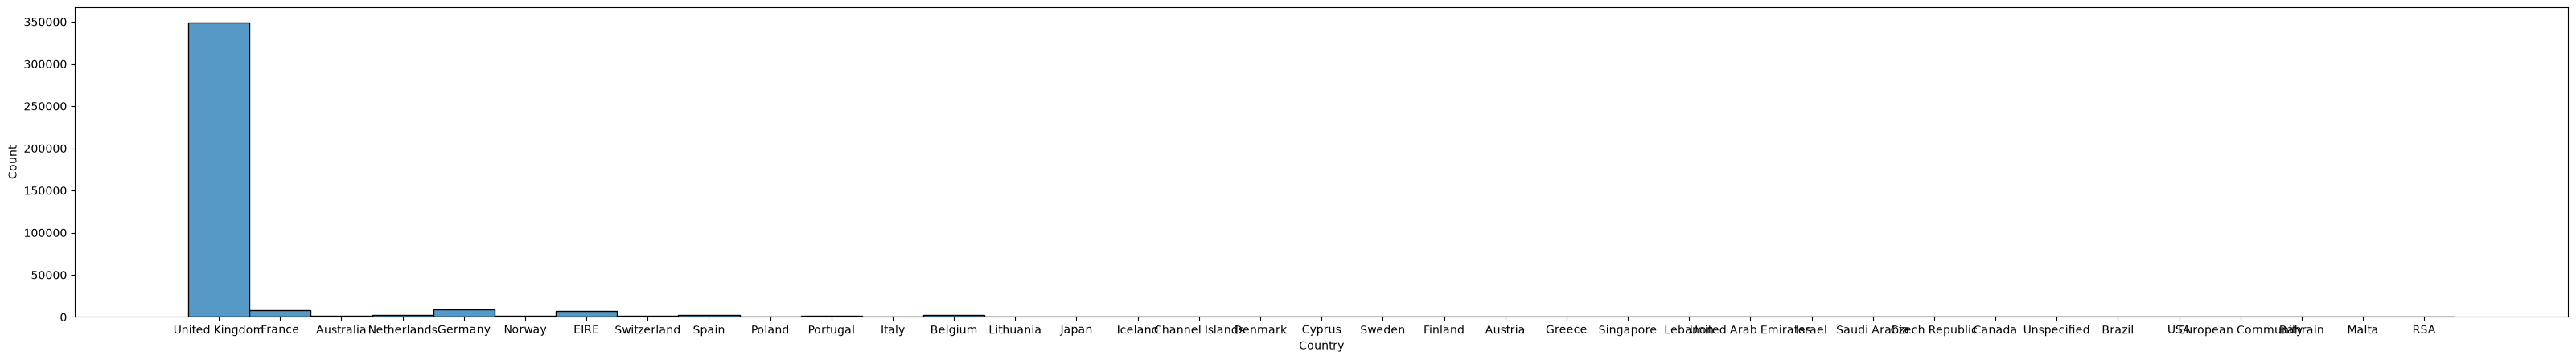

In [20]:
import matplotlib.pyplot as plt
plt.figure(figsize=[40,5])

sns.histplot(df['Country'])

In [21]:
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin

class CustomerFeatureExtractor(BaseEstimator, TransformerMixin):
    def __init__(self, reference_date=None, iqr_multiplier=1.5):
        self.reference_date = reference_date
        self.iqr_multiplier = iqr_multiplier

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        df = X.copy()
        
        # 1. Basic Cleaning
        df = df.dropna(subset=['CustomerID'])
        df = df[~df['InvoiceNo'].astype(str).str.startswith('C')]
        
        # 2. Calculations
        df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
        df['Quantity'] = pd.to_numeric(df['Quantity'], errors='coerce').fillna(0)
        df['UnitPrice'] = pd.to_numeric(df['UnitPrice'], errors='coerce').fillna(0.0)
        df['Amount'] = df['Quantity'] * df['UnitPrice']

        ref_date = self.reference_date or (df['InvoiceDate'].max() + pd.Timedelta(days=1))

        # 3. Aggregation per Customer
        customer_df = df.groupby('CustomerID').agg(
            recency=('InvoiceDate', lambda x: (ref_date - x.max()).days),
            min_amount=('Amount', 'min'),
            max_amount=('Amount', 'max'),
            total_amount=('Amount', 'sum'),
            frequency=('InvoiceNo', 'nunique')
        ).reset_index()

        # 4. Apply IQR Filtering on max_amount
        if self.iqr_multiplier is not None:
            q1 = customer_df['max_amount'].quantile(0.25)
            q3 = customer_df['max_amount'].quantile(0.75)
            iqr = q3 - q1
            upper_bound = q3 + (self.iqr_multiplier * iqr)
            
            # Retain non-whales
            customer_df = customer_df[customer_df['max_amount'] <= upper_bound]

        return customer_df.set_index('CustomerID')

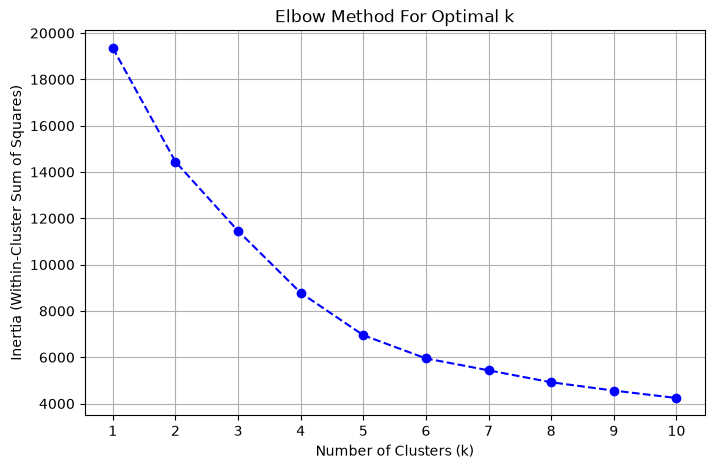

In [22]:
preprocessor_pipeline = Pipeline(steps=[
    ('customer_features', CustomerFeatureExtractor()),
    ('scaler', StandardScaler())
])

# Fit and transform the raw transaction DataFrame
X_scaled = preprocessor_pipeline.fit_transform(X_train)

# 2. Compute inertia (distortion) for a range of k values
inertia = []
k_range = range(1, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

# 3. Plot the Elbow Curve
plt.figure(figsize=(8, 5))
plt.plot(k_range, inertia, marker='o', linestyle='--', color='b')
plt.title('Elbow Method For Optimal k')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia (Within-Cluster Sum of Squares)')
plt.xticks(k_range)
plt.grid(True)
plt.show()

In [25]:
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(X_scaled)

In [26]:
customer_df = CustomerFeatureExtractor().transform(X_train)
customer_df['Cluster'] = cluster_labels

# 4. Map dominant Country to each CustomerID from raw dataset
# (Assigns the most frequent country for customers with multiple locations)
customer_countries = (
    X_train.dropna(subset=['CustomerID'])
    .groupby('CustomerID')['Country']
    .agg(lambda x: x.mode()[0] if not x.empty else 'Unknown')
)
customer_df['Country'] = customer_df.index.map(customer_countries)

# ---------------------------------------------------------
# Part 1: Cluster Profiling Summary (Averages & Dominant Country)
# ---------------------------------------------------------
cluster_profile = customer_df.groupby('Cluster').agg(
    customer_count=('recency', 'count'),
    avg_recency=('recency', 'mean'),
    avg_total_amount=('total_amount', 'mean'),
    avg_min_amount=('min_amount', 'mean'),
    avg_max_amount=('max_amount', 'mean'),
    avg_frequency=('frequency', 'mean'),
    top_country=('Country', lambda x: x.mode()[0]),
    top_country_pct=('Country', lambda x: f"{(x.value_counts().iloc[0] / len(x)) * 100:.1f}%")
).reset_index()

print("=== K-MEANS CLUSTER PROFILES ===")
print(cluster_profile.to_string(index=False))

# ---------------------------------------------------------
# Part 2: Detailed Country Distribution Per Cluster
# ---------------------------------------------------------
print("\n=== TOP 3 COUNTRIES PER CLUSTER ===")
for cluster_id in sorted(customer_df['Cluster'].unique()):
    top_countries = (
        customer_df[customer_df['Cluster'] == cluster_id]['Country']
        .value_counts(normalize=True)
        .head(3) * 100
    )
    print(f"\nCluster {cluster_id}:")
    for country, pct in top_countries.items():
        print(f"  - {country}: {pct:.2f}%")

=== K-MEANS CLUSTER PROFILES ===
 Cluster  customer_count  avg_recency  avg_total_amount  avg_min_amount  avg_max_amount  avg_frequency    top_country top_country_pct
       0             904   251.601770        369.161273        7.556882       45.728097       1.456858 United Kingdom           91.4%
       1            2075    45.860241        793.866218        5.083573       44.057788       2.896386 United Kingdom           92.6%
       2             644    56.560559       1831.934068        6.841739      135.265963       4.475155 United Kingdom           86.0%
       3             199    15.507538       5884.717487        2.955327      106.260704      16.366834 United Kingdom           89.4%
       4              49   187.367347        304.014286      114.292653      135.479184       1.306122 United Kingdom          100.0%

=== TOP 3 COUNTRIES PER CLUSTER ===

Cluster 0:
  - United Kingdom: 91.37%
  - France: 1.99%
  - Germany: 1.44%

Cluster 1:
  - United Kingdom: 92.58%
  - France:

RecursionError: maximum recursion depth exceeded

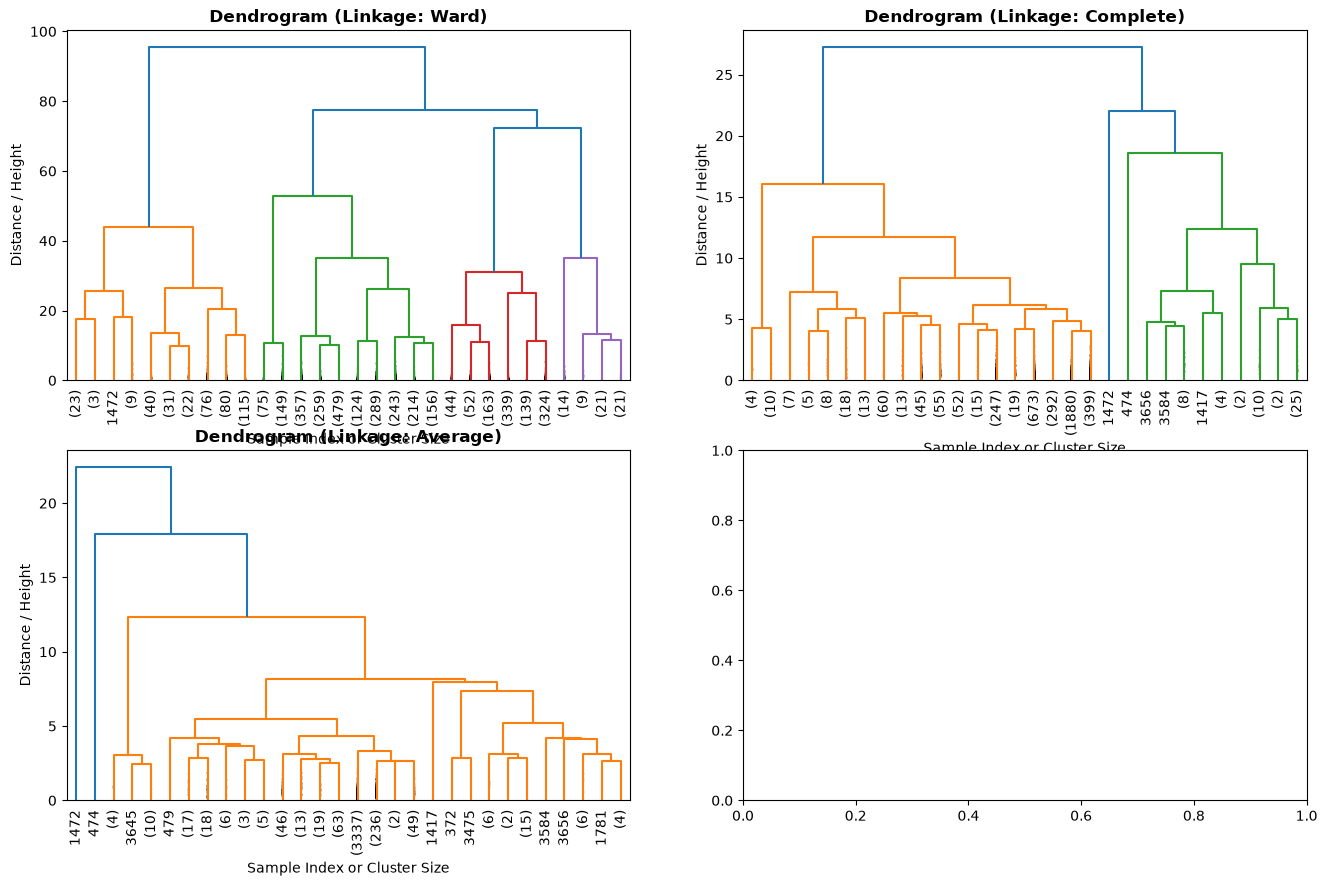

In [28]:
preprocessor = Pipeline(steps=[
    ('customer_features', CustomerFeatureExtractor()),
    ('scaler', StandardScaler())
])

X_scaled = preprocessor.fit_transform(X_train)

# ---------------------------------------------------------
# Part 1: Plot Dendrograms for Different Linkage Strategies
# ---------------------------------------------------------
linkage_methods = ['ward', 'complete', 'average', 'single']

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.ravel()

for i, method in enumerate(linkage_methods):
    # Compute hierarchical linkage matrix
    Z = linkage(X_scaled, method=method)
    
    # Plot dendrogram (truncated to show top 30 merged clusters)
    dendrogram(
        Z,
        ax=axes[i],
        truncate_mode='lastp',
        p=30,
        leaf_rotation=90.,
        leaf_font_size=10.,
        show_contracted=True
    )
    axes[i].set_title(f'Dendrogram (Linkage: {method.capitalize()})', fontsize=12, fontweight='bold')
    axes[i].set_xlabel('Sample Index or Cluster Size')
    axes[i].set_ylabel('Distance / Height')

plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# Part 2: Compare Linkage Strategies with Silhouette Scores
# ---------------------------------------------------------
n_clusters = 5  # Chosen based on elbow/dendrogram inspection

print(f"--- Silhouette Score Comparison (n_clusters = {n_clusters}) ---")
for method in linkage_methods:
    # Single linkage requires euclidean distance in Scikit-Learn
    model = AgglomerativeClustering(n_clusters=n_clusters, linkage=method)
    cluster_labels = model.fit_predict(X_scaled)
    
    score = silhouette_score(X_scaled, cluster_labels)
    print(f"Linkage: {method.capitalize():<10} | Silhouette Score: {score:.4f}")